In [2]:
import pandas as pd
import numpy as np

In [3]:
def get_geo_from_path(x):
    litems = x.replace(" ", "").split(">")
    check = ['Asia', 'US', 'Global', 'APAC']
    for c in check:
        if c in litems:
            return c
    return 'Unknown'

def reset_rev_rank(segs, col='rev_rank'):
    segs = segs.sort_values(['Third_Party_Data_Provider_Id', 'revenue'], ascending=[False, False])
    rev_rank = 0
    dp=None
    ranks = []
    for idx, row in segs.iterrows():
        if dp != row['Third_Party_Data_Provider_Id']:
            # reset
            dp = row['Third_Party_Data_Provider_Id']
            rev_rank = 0
        rev_rank += 1
        ranks.append(rev_rank)
    segs[col] = ranks
    return segs 

In [4]:
def exclude_segs(df, segs):
    return pd.DataFrame(df[~df.Full_Path.isin(segs)], copy=True)

In [5]:
base_PoM_default = {'dav2shreths':0.16, 'sharethis': 0.15}
rev_rank = {'dav2shreths':0, 'sharethis': 0}

In [12]:
ttd_path = "/Users/ravirajan/Projects/TTD"
in_p = f"{ttd_path}/Ranked_by_Revenue.csv"
#out_p = f"{ttd_path}/Price_Expt_Assignments.csv"
out_int_p = f"{ttd_path}/Price_Expt_Intermediate.csv"
#out_p = f"{ttd_path}/Price_Expt_Assignments2.csv" # good
out_p = f"{ttd_path}/Price_Expt_Assignments2.csv.test"
aud_to_exclude_p = [f"{ttd_path}/Price_Expt_Assignments.csv"]

n=120 # 66
assert(out_p != in_p)
assert(out_p != out_int_p)

In [13]:
segs1 = pd.read_csv(in_p)
segs1.head()

,Third_Party_Data_Provider_Id,Full_Path,revenue,rev_rank
0,sharethis,Global > people & society > social issues & ad...,13214.33,1
1,sharethis,B2B > Industry > Food Services,10172.36,2
2,sharethis,US > Health Interest > Dry Eyes,9899.08,3
3,sharethis,US > shopping > apparel > footwear,6607.92,4
4,sharethis,Global > Validated Demographic > Age > 18-44,3901.50,5


In [14]:
segs1['revenue'].describe(percentiles=[0.05,0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.97, 0.99])

count     4697.000000
mean        43.954748
std        347.996775
min          0.000000
5%           0.000000
10%          0.000000
25%          0.000000
50%          0.160000
75%          4.100000
90%         38.140000
95%        133.566000
97%        313.764400
99%        916.132800
max      13214.330000
Name: revenue, dtype: float64

In [15]:
segs1.groupby('Third_Party_Data_Provider_Id').size()

Third_Party_Data_Provider_Id
dav2shreths    2146
sharethis      3580
dtype: int64

In [16]:
segs1.groupby('Third_Party_Data_Provider_Id')['revenue'].describe(percentiles=[0.05,0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.97, 0.99])

,count,mean,std,min,5%,10%,25%,50%,75%,90%,95%,97%,99%,max
Third_Party_Data_Provider_Id,,,,,,,,,,,,,,
dav2shreths,1638.0,15.527387,110.757848,0.0,0.0,0.0,0.00,0.07,1.315,14.085,43.0245,78.2622,306.5667,2421.51
sharethis,3059.0,59.176721,422.773777,0.0,0.0,0.0,0.01,0.29,7.115,60.330,226.7820,469.6362,1002.3114,13214.33


### filter GEO

In [18]:
segs1['geo'] = segs1.Full_Path.apply(lambda x: get_geo_from_path(x))

In [19]:
segs1.groupby('Third_Party_Data_Provider_Id')['revenue'].max()

Third_Party_Data_Provider_Id
dav2shreths     2421.51
sharethis      13214.33
Name: revenue, dtype: float64

In [20]:
segs = segs1[segs1['geo'] == 'Global']
segs.head()

,Third_Party_Data_Provider_Id,Full_Path,revenue,rev_rank,geo
0,sharethis,Global > people & society > social issues & ad...,13214.33,1,Global
4,sharethis,Global > Validated Demographic > Age > 18-44,3901.50,5,Global
5,sharethis,Global > Validated Demographic > Gender > Female,3213.92,6,Global
6,sharethis,Global > travel > tourist destinations > mount...,2692.62,7,Global
10,sharethis,Global > law & government > legal > accident &...,2057.02,11,Global


In [21]:
# need to do this bit again after filtering revenue
segs = reset_rev_rank(segs, col='rev_rank')
segs.head()

,Third_Party_Data_Provider_Id,Full_Path,revenue,rev_rank,geo
0,sharethis,Global > people & society > social issues & ad...,13214.33,1,Global
4,sharethis,Global > Validated Demographic > Age > 18-44,3901.50,2,Global
5,sharethis,Global > Validated Demographic > Gender > Female,3213.92,3,Global
6,sharethis,Global > travel > tourist destinations > mount...,2692.62,4,Global
10,sharethis,Global > law & government > legal > accident &...,2057.02,5,Global


In [22]:
segs['group'] = segs['rev_rank'].apply(lambda x: int(np.floor((x-1)/3)))
#segs['group'] = segs.reset_index()['index'].apply(lambda x: int(np.floor((x)/3)))

In [23]:
segs.groupby('Third_Party_Data_Provider_Id')['rev_rank'].describe()

,count,mean,std,min,25%,50%,75%,max
Third_Party_Data_Provider_Id,,,,,,,,
dav2shreths,2143.0,1072.0,618.775134,1.0,536.50,1072.0,1607.50,2143.0
sharethis,1020.0,510.5,294.592939,1.0,255.75,510.5,765.25,1020.0


In [24]:
# Returns a new DataFrame where rows within each group are shuffled
shuffled_df = segs.groupby(['Third_Party_Data_Provider_Id', 'group'], group_keys=False).apply(lambda x: x.sample(frac=1)).sort_values(['Third_Party_Data_Provider_Id', 'group'])

/var/folders/wt/bzrqdlb17zv7h4r1y9jqpg_w0000gp/T/ipykernel_24328/4149201708.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  shuffled_df = segs.groupby(['Third_Party_Data_Provider_Id', 'group'], group_keys=False).apply(lambda x: x.sample(frac=1)).sort_values(['Third_Party_Data_Provider_Id', 'group'])


In [25]:
shuffled_df

,Third_Party_Data_Provider_Id,Full_Path,revenue,rev_rank,geo,group
3580,dav2shreths,Data Alliance > Business & Finance > Interest ...,2421.51,1,Global,0
3582,dav2shreths,Data Alliance > Business & Finance > Interest ...,1336.34,3,Global,0
3581,dav2shreths,Data Alliance > Demographic > Interest > Globa...,1983.75,2,Global,0
3584,dav2shreths,Data Alliance > Travel > Interest > Global > A...,1081.20,5,Global,1
3585,dav2shreths,Data Alliance > Travel > Interest > Global > D...,974.94,6,Global,1
...,...,...,...,...,...,...
3302,sharethis,Global > sports > sporting goods > table tenni...,NaN,1017,Global,338
3301,sharethis,Global > sports > sporting goods > sports memo...,NaN,1016,Global,338
3304,sharethis,Global > sports > team sports,NaN,1019,Global,339
3305,sharethis,Global > sports > team sports > handball,NaN,1020,Global,339


In [26]:
from itertools import cycle

values = [1, 0, -1]
pool = cycle(values)
shuffled_df['assignment'] = [next(pool) for _ in range(len(shuffled_df))]

In [27]:
shuffled_df.groupby('Third_Party_Data_Provider_Id')['group'].max()

Third_Party_Data_Provider_Id
dav2shreths    714
sharethis      339
Name: group, dtype: int64

In [28]:
gp_price = {}

#incr = [0.01, 0.02, 0.03]
incr = [0.05]

for g in np.arange(shuffled_df['group'].max() + 1):
    gp_price[g] = np.random.choice(incr)

gp_price_df = pd.DataFrame([gp_price]).T
gp_price_df.columns=["incr"]

final_df = shuffled_df.set_index('group').join(gp_price_df).reset_index()

In [29]:
final_df
#final_df.to_csv(out_int_p)

,group,Third_Party_Data_Provider_Id,Full_Path,revenue,rev_rank,geo,assignment,incr
0,0,dav2shreths,Data Alliance > Business & Finance > Interest ...,2421.51,1,Global,1,0.05
1,0,dav2shreths,Data Alliance > Business & Finance > Interest ...,1336.34,3,Global,0,0.05
2,0,dav2shreths,Data Alliance > Demographic > Interest > Globa...,1983.75,2,Global,-1,0.05
3,1,dav2shreths,Data Alliance > Travel > Interest > Global > A...,1081.20,5,Global,1,0.05
4,1,dav2shreths,Data Alliance > Travel > Interest > Global > D...,974.94,6,Global,0,0.05
...,...,...,...,...,...,...,...,...
3158,338,sharethis,Global > sports > sporting goods > table tenni...,NaN,1017,Global,-1,0.05
3159,338,sharethis,Global > sports > sporting goods > sports memo...,NaN,1016,Global,1,0.05
3160,339,sharethis,Global > sports > team sports,NaN,1019,Global,0,0.05
3161,339,sharethis,Global > sports > team sports > handball,NaN,1020,Global,-1,0.05


In [179]:
final_df.groupby('Third_Party_Data_Provider_Id').size()

Third_Party_Data_Provider_Id
dav2shreths    2143
sharethis      1020
dtype: int64

In [55]:
final_df.groupby('Third_Party_Data_Provider_Id')['revenue'].sum()

Third_Party_Data_Provider_Id
dav2shreths    25433.08
sharethis      69416.78
Name: revenue, dtype: float64

In [30]:
final_df.groupby('Third_Party_Data_Provider_Id')['revenue'].describe(percentiles=[0.05,0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.97, 0.99])

,count,mean,std,min,5%,10%,25%,50%,75%,90%,95%,97%,99%,max
Third_Party_Data_Provider_Id,,,,,,,,,,,,,,
dav2shreths,1636.0,15.545892,110.824303,0.0,0.0,0.00,0.0,0.07,1.3275,14.095,43.0275,78.4410,306.5685,2421.51
sharethis,810.0,85.699728,536.745068,0.0,0.0,0.01,0.2,4.62,27.6400,127.424,288.9390,645.4793,1360.3478,13214.33


In [32]:
st = final_df[final_df['Third_Party_Data_Provider_Id'] == 'sharethis']
da = final_df[final_df['Third_Party_Data_Provider_Id'] == 'dav2shreths']


n2 = int(n/2)

mx_st = st['group'].max()
mx_da = da['group'].max()

md_st = int(mx_st / 2)
md_da = int(mx_da / 2)

top = pd.DataFrame(final_df[final_df['group'] < n], copy=True)
top['bucket'] = 'high'

bottom = pd.DataFrame(pd.concat([
    st[ (st['group'] > (mx_st - n)) ],
    da[ (da['group'] > (mx_da - n)) ]
    ]), copy=True)
bottom['bucket'] = 'low'
# iloc[:n] coz there are lots of zero revenues with the same rank!!

med = pd.DataFrame(pd.concat([ 
    st[ (st['group'] >= (md_st - n2) ) & (st['group'] <= (md_st + n2) ) ], 
    da[ (da['group'] >= (md_da - n2) ) & (da['group'] <= (md_da + n2) ) ]
    ] ), copy=True)

med['bucket'] = 'medium'

joined_df = pd.concat([top, med, bottom])

# check

valid = pd.DataFrame(joined_df.groupby(['Third_Party_Data_Provider_Id', 'group']).size() == 3)
valid = valid[valid == True].dropna()

selected_df = joined_df.set_index(['Third_Party_Data_Provider_Id', 'group']).join(valid, how='inner').reset_index().sort_values(['Third_Party_Data_Provider_Id', 'rev_rank'])
del selected_df[0]

In [33]:
selected_df.head()

,Third_Party_Data_Provider_Id,group,Full_Path,revenue,rev_rank,geo,assignment,incr,bucket
0,dav2shreths,0,Data Alliance > Business & Finance > Interest ...,2421.51,1,Global,1,0.05,high
2,dav2shreths,0,Data Alliance > Demographic > Interest > Globa...,1983.75,2,Global,-1,0.05,high
1,dav2shreths,0,Data Alliance > Business & Finance > Interest ...,1336.34,3,Global,0,0.05,high
5,dav2shreths,1,Data Alliance > Demographic > Interest > Globa...,1230.68,4,Global,-1,0.05,high
3,dav2shreths,1,Data Alliance > Travel > Interest > Global > A...,1081.20,5,Global,1,0.05,high


In [35]:
selected_df.groupby(['Third_Party_Data_Provider_Id', 'bucket'])['revenue'].describe(percentiles=[0.05,0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.97, 0.99])

count        mean         std    min  \
Third_Party_Data_Provider_Id bucket                                         
dav2shreths                  high    360.0   69.930639  228.326393   2.14   
                             low       0.0         NaN         NaN    NaN   
                             medium  363.0    0.016033    0.012754   0.00   
sharethis                    high    327.0  209.486972  830.150023  10.09   
                             low     120.0    0.006417    0.009509   0.00   
                             medium  300.0    2.083667    2.110580   0.07   

                                         5%     10%    25%     50%       75%  \
Third_Party_Data_Provider_Id bucket                                            
dav2shreths                  high     2.440   2.688   4.68  12.145   37.4025   
                             low        NaN     NaN    NaN     NaN       NaN   
                             medium   0.000   0.000   0.01   0.010    0.0200   
sharethis                    high    11.982  12.972  20.34  40.820  125.7800   
                             low      0.000   0.000   0.00   0.000    0.0100   
                             medium   0.110   0.140   0.34   1.140    3.6275   

                                         90%       95%        97%        99%  \
Third_Party_Data_Provider_Id bucket                                            
dav2shreths                  high    118.523  275.2265   546.2327  1142.4868   
                             low         NaN       NaN        NaN        NaN   
                             medium    0.040    0.0400     0.0400     0.0400   
sharethis                    high    348.560  900.1960  1165.6858  2527.3640   
                             low       0.020    0.0300     0.0300     0.0300   
                             medium    5.506    6.8120     7.0018     7.3000   

                                          max  
Third_Party_Data_Provider_Id bucket            
dav2shreths                  high     2421.51  
                             low          NaN  
                             medium      0.05  
sharethis                    high    13214.33  
                             low         0.03  
                             medium      7.52

In [40]:
final_df.groupby('Third_Party_Data_Provider_Id')['revenue'].describe(percentiles=[0.05,0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.97, 0.99])

,count,mean,std,min,5%,10%,25%,50%,75%,90%,95%,97%,99%,max
Third_Party_Data_Provider_Id,,,,,,,,,,,,,,
dav2shreths,1636.0,15.545892,110.824303,0.0,0.0,0.00,0.0,0.07,1.3275,14.095,43.0275,78.4410,306.5685,2421.51
sharethis,810.0,85.699728,536.745068,0.0,0.0,0.01,0.2,4.62,27.6400,127.424,288.9390,645.4793,1360.3478,13214.33


### Hard coded range -> low < 0.05, high > 10, med is everything else

Third_Party_Data_Provider_Id
dav2shreths    Axes(0.125,0.11;0.775x0.77)
sharethis      Axes(0.125,0.11;0.775x0.77)
Name: revenue, dtype: object

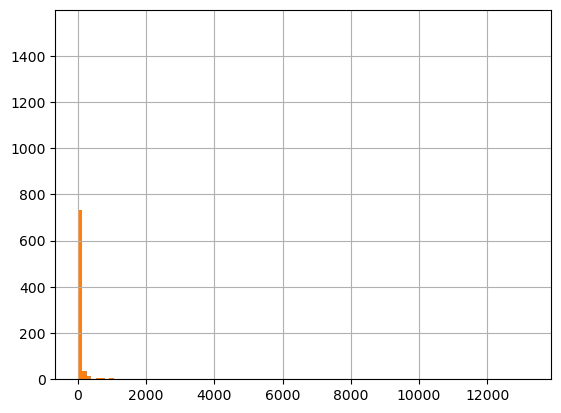

In [50]:
final_df.groupby('Third_Party_Data_Provider_Id')['revenue'].hist(bins=100)

Third_Party_Data_Provider_Id
dav2shreths    Axes(0.125,0.11;0.775x0.77)
sharethis      Axes(0.125,0.11;0.775x0.77)
Name: log_rev, dtype: object

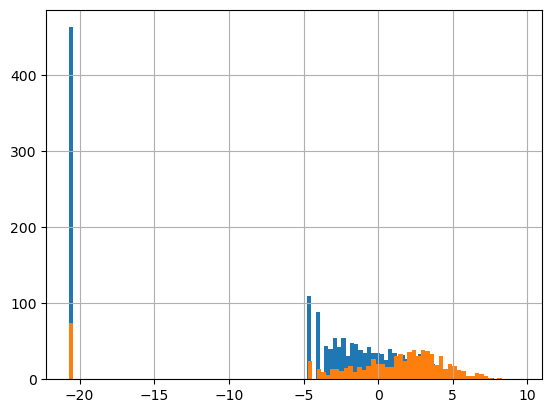

In [54]:
final_df['rev_adj'] = final_df['revenue'] + 1e-9
final_df['log_rev'] = np.log(final_df['rev_adj'])
final_df.groupby('Third_Party_Data_Provider_Id')['log_rev'].hist(bins=100)

## retain orig assignments

In [192]:
import os
  
selected_df0 = pd.DataFrame(selected_df, copy=True)
aud_2_retain = pd.concat([pd.read_csv(f) for f in aud_to_exclude_p if os.path.exists(f)])

if not aud_2_retain.empty:
    print ("found audiences to retain")
    selected_df = exclude_segs(selected_df, aud_2_retain.Full_Path)
    selected_df = pd.concat([aud_2_retain, selected_df])

found audiences to retain


In [193]:
selected_df.head()

,Unnamed: 0,Third_Party_Data_Provider_Id,group,Full_Path,revenue,rev_rank,geo,assignment,incr,bucket
0,0.0,dav2shreths,0,Data Alliance > Business & Finance > Interest ...,2421.51,1,Global,1,0.05,high
1,2.0,dav2shreths,0,Data Alliance > Demographic > Interest > Globa...,1983.75,2,Global,-1,0.05,high
2,1.0,dav2shreths,0,Data Alliance > Business & Finance > Interest ...,1336.34,3,Global,0,0.05,high
3,4.0,dav2shreths,1,Data Alliance > Demographic > Interest > Globa...,1230.68,4,Global,0,0.05,high
4,3.0,dav2shreths,1,Data Alliance > Travel > Interest > Global > A...,1081.20,5,Global,1,0.05,high


In [203]:
selected_df0.groupby(['Third_Party_Data_Provider_Id', 'bucket']).size()

Third_Party_Data_Provider_Id  bucket
dav2shreths                   high      360
                              low       357
                              medium    363
sharethis                     high      327
                              low       330
                              medium    300
dtype: int64

In [201]:
selected_df.groupby(['Third_Party_Data_Provider_Id', 'bucket']).size()

Third_Party_Data_Provider_Id  bucket
dav2shreths                   high      360
                              low       357
                              medium    363
sharethis                     high      327
                              low       330
                              medium    300
dtype: int64

In [202]:
aud_2_retain.groupby(['Third_Party_Data_Provider_Id', 'bucket']).size()

Third_Party_Data_Provider_Id  bucket
dav2shreths                   high      198
                              low       195
                              medium    201
sharethis                     high      198
                              low       198
                              medium    201
dtype: int64

In [184]:
selected_df.groupby(['Third_Party_Data_Provider_Id', 'bucket']).size() % 3

Third_Party_Data_Provider_Id  bucket
dav2shreths                   high      0
                              low       0
                              medium    0
sharethis                     high      0
                              low       0
                              medium    0
dtype: int64

In [206]:
selected_df.groupby(['Third_Party_Data_Provider_Id']).size()

Third_Party_Data_Provider_Id
dav2shreths    1080
sharethis       957
dtype: int64

In [207]:
selected_df.groupby(['Third_Party_Data_Provider_Id', 'assignment']).size()

Third_Party_Data_Provider_Id  assignment
dav2shreths                   -1            360
                               0            360
                               1            360
sharethis                     -1            319
                               0            319
                               1            319
dtype: int64

In [208]:
selected_df.shape[0] % 3

0

In [209]:
selected_df.groupby(['Third_Party_Data_Provider_Id', 'bucket'])[['revenue']].describe()

revenue                                 \
                                      count        mean         std    min   
Third_Party_Data_Provider_Id bucket                                          
dav2shreths                  high     360.0   69.930639  228.326393   2.14   
                             low        0.0         NaN         NaN    NaN   
                             medium   363.0    0.016033    0.012754   0.00   
sharethis                    high     327.0  209.486972  830.150023  10.09   
                             low      120.0    0.006417    0.009509   0.00   
                             medium   300.0    2.083667    2.110580   0.07   

                                                                        
                                       25%     50%       75%       max  
Third_Party_Data_Provider_Id bucket                                     
dav2shreths                  high     4.68  12.145   37.4025   2421.51  
                             low       NaN     NaN       NaN       NaN  
                             medium   0.01   0.010    0.0200      0.05  
sharethis                    high    20.34  40.820  125.7800  13214.33  
                             low      0.00   0.000    0.0100      0.03  
                             medium   0.34   1.140    3.6275      7.52

In [210]:
out_p

'../../Projects/TTD/Price_Expt_Assignments2.csv'

In [ ]:
selected_for_output = selected_df[selected_df

In [211]:
#selected_df.to_csv(out_p)